# EfficientNetV2-S — Person-wise Driver Behaviour Classification

This notebook benchmarks a pretrained torchvision EfficientNetV2-S on the existing five-class dataset.

**Person-wise split expected:** `Train/Person1...Person7`, `Validation/Person8`, `Test/Person9`.

- Uses ImageNet pretrained weights.
- Keeps the five existing class labels.
- Selects the best checkpoint using validation macro-F1.
- Evaluates the test participant only after training is complete.
- Saves metrics, classification report, confusion matrix, and training curves.

**Important:** Do not change the test split or use Person9 results to tune hyperparameters. Run this with the same person-wise split as the custom CNN for a fair comparison.

## 1. Imports

In [1]:
import random
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from tqdm.auto import tqdm

c:\Btech\SEM5\cuda\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration and reproducibility

In [3]:
# Update this only if your dataset is stored elsewhere.
ROOT_DIR = Path(r"C:\\Btech\\SEM5\\cuda\\DL\\Dataset")

TRAIN_DIR = ROOT_DIR / "Train"
VAL_DIR   = ROOT_DIR / "Validation"
TEST_DIR  = ROOT_DIR / "Test"

CLASSES = ["Distraction", "Drinking", "Normal", "Phone", "Sleeping"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

SEED = 42
BATCH_SIZE = 4        # Conservative starting point for RTX 4060
NUM_WORKERS = 0       # Keep 0 for Windows/Jupyter stability
EPOCHS = 25
EARLY_STOPPING_PATIENCE = 6

# Aspect-ratio-preserving resize: original images are approximately 854x480.
# EfficientNetV2-S accepts this spatial size and uses adaptive pooling.
IMAGE_HEIGHT = 384
IMAGE_WIDTH = 684

BACKBONE_LR = 3e-5
HEAD_LR = 3e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.05

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"

print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for split_name, split_dir in [("Train", TRAIN_DIR), ("Validation", VAL_DIR), ("Test", TEST_DIR)]:
    print(f"{split_name} directory exists:", split_dir.exists())
    if not split_dir.exists():
        raise FileNotFoundError(f"Check dataset path: {split_dir}")

Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Train directory exists: True
Validation directory exists: True
Test directory exists: True


## 3. Build image index and verify person-wise separation

In [4]:
def build_dataframe(split_path):
    rows = []
    person_folders = sorted(p for p in split_path.iterdir() if p.is_dir())

    for person_folder in person_folders:
        person_name = person_folder.name

        for class_name in CLASSES:
            class_folder = person_folder / class_name
            if not class_folder.exists():
                continue

            for image_path in class_folder.iterdir():
                if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    rows.append({
                        "path": str(image_path),
                        "person": person_name,
                        "class": class_name,
                        "label": CLASS_TO_IDX[class_name]
                    })

    return pd.DataFrame(rows)

train_df = build_dataframe(TRAIN_DIR)
val_df = build_dataframe(VAL_DIR)
test_df = build_dataframe(TEST_DIR)

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("At least one split is empty. Check folder structure and class-folder names.")

train_people = set(train_df["person"].unique())
val_people = set(val_df["person"].unique())
test_people = set(test_df["person"].unique())

print("Train images:", len(train_df), "| participants:", sorted(train_people))
print("Validation images:", len(val_df), "| participants:", sorted(val_people))
print("Test images:", len(test_df), "| participants:", sorted(test_people))

assert train_people.isdisjoint(val_people), "Participant leakage between train and validation!"
assert train_people.isdisjoint(test_people), "Participant leakage between train and test!"
assert val_people.isdisjoint(test_people), "Participant leakage between validation and test!"

print("\nParticipant-wise separation check passed.")

print("\nTraining class counts:")
print(train_df["class"].value_counts().reindex(CLASSES, fill_value=0))
print("\nValidation class counts:")
print(val_df["class"].value_counts().reindex(CLASSES, fill_value=0))
print("\nTest class counts:")
print(test_df["class"].value_counts().reindex(CLASSES, fill_value=0))

Train images: 25779 | participants: ['Person1', 'Person2', 'Person3', 'Person4', 'Person5', 'Person6', 'Person7']
Validation images: 3548 | participants: ['Person8']
Test images: 3565 | participants: ['Person9']

Participant-wise separation check passed.

Training class counts:
class
Distraction    4836
Drinking       5736
Normal         4895
Phone          5333
Sleeping       4979
Name: count, dtype: int64

Validation class counts:
class
Distraction    712
Drinking       636
Normal         633
Phone          901
Sleeping       666
Name: count, dtype: int64

Test class counts:
class
Distraction    696
Drinking       642
Normal         709
Phone          819
Sleeping       699
Name: count, dtype: int64


## 4. Image transformations and datasets

In [5]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_HEIGHT, IMAGE_WIDTH)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

class DriverDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row["path"]) as img:
            image = img.convert("RGB")
        image = self.transform(image)
        return image, int(row["label"])

train_dataset = DriverDataset(train_df, train_transform)
val_dataset = DriverDataset(val_df, eval_transform)
test_dataset = DriverDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=USE_AMP
)

print("Batches:", len(train_loader), len(val_loader), len(test_loader))

Batches: 6445 887 892


## 5. Class weights

In [6]:
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"].to_numpy()
)
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)

print("Class weights:")
for class_name, weight in zip(CLASSES, class_weights_np):
    print(f"{class_name:15s}: {weight:.3f}")

Class weights:
Distraction    : 1.066
Drinking       : 0.899
Normal         : 1.053
Phone          : 0.967
Sleeping       : 1.036


## 6. Load pretrained EfficientNetV2-S

In [7]:
# ImageNet pretrained weights are downloaded on the first run if not cached.
weights = models.EfficientNet_V2_S_Weights.DEFAULT
model = models.efficientnet_v2_s(weights=weights)

# Replace the original 1000-class ImageNet head with our 5-class classifier.
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, len(CLASSES))
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(model.classifier)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Users\rakes/.cache\torch\hub\checkpoints\efficientnet_v2_s-dd5fe13b.pth
100%|██████████| 82.7M/82.7M [01:13<00:00, 1.19MB/s]


Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)
Total parameters: 20,183,893
Trainable parameters: 20,183,893


## 7. Loss, optimizer, scheduler and AMP

In [8]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=LABEL_SMOOTHING
)

# Lower learning rate for pretrained feature extractor; higher rate for new classifier.
optimizer = torch.optim.AdamW(
    [
        {"params": model.features.parameters(), "lr": BACKBONE_LR},
        {"params": model.classifier.parameters(), "lr": HEAD_LR}
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=2,
    threshold=1e-3, min_lr=1e-6
)

scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

print("Backbone LR:", BACKBONE_LR)
print("Classifier LR:", HEAD_LR)
print("AMP enabled:", USE_AMP)

Backbone LR: 3e-05
Classifier LR: 0.0003
AMP enabled: True


## 8. Training and validation

In [10]:
RESULTS_DIR = Path("EfficientNetV2S_Personwise_Results")
RESULTS_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = RESULTS_DIR / "best_efficientnetv2_s_personwise.pth"

history = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_f1": [], "val_f1": []
}

best_val_f1 = -1.0
epochs_without_improvement = 0
best_state = copy.deepcopy(model.state_dict())

for epoch in range(EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 60)

    # TRAIN
    model.train()
    running_loss = 0.0
    train_true, train_pred = [], []

    for images, labels in tqdm(train_loader, desc="Training", leave=False):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_true.extend(labels.detach().cpu().numpy())
        train_pred.extend(preds.detach().cpu().numpy())

    train_loss = running_loss / max(1, len(train_loader))
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(train_true, train_pred, average="macro", zero_division=0)

    # VALIDATION
    model.eval()
    val_running_loss = 0.0
    val_true, val_pred = [], []

    with torch.inference_mode():
        for images, labels in tqdm(val_loader, desc="Validation", leave=False):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_running_loss += loss.item()
            preds = outputs.argmax(dim=1)
            val_true.extend(labels.cpu().numpy())
            val_pred.extend(preds.cpu().numpy())

    val_loss = val_running_loss / max(1, len(val_loader))
    val_acc = accuracy_score(val_true, val_pred)
    val_f1 = f1_score(val_true, val_pred, average="macro", zero_division=0)

    scheduler.step(val_f1)
    current_lrs = [group["lr"] for group in optimizer.param_groups]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0
        best_state = copy.deepcopy(model.state_dict())

        torch.save({
            "model_state_dict": best_state,
            "classes": CLASSES,
            "class_to_idx": CLASS_TO_IDX,
            "best_val_macro_f1": best_val_f1,
            "image_size": (IMAGE_HEIGHT, IMAGE_WIDTH),
            "architecture": "torchvision.efficientnet_v2_s"
        }, CHECKPOINT_PATH)
        status = "Best checkpoint saved"
    else:
        epochs_without_improvement += 1
        status = f"No improvement: {epochs_without_improvement}/{EARLY_STOPPING_PATIENCE}"

    elapsed = time.time() - epoch_start
    print(f"Train | loss {train_loss:.4f} | acc {train_acc:.4f} | macro-F1 {train_f1:.4f}")
    print(f"Val   | loss {val_loss:.4f} | acc {val_acc:.4f} | macro-F1 {val_f1:.4f}")
    print(f"LR backbone: {current_lrs[0]:.2e} | head: {current_lrs[1]:.2e}")
    print(f"{status} | epoch time: {elapsed/60:.1f} min")

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping.")
        break

print("\nTraining finished.")
print(f"Best validation macro-F1: {best_val_f1:.4f}")
print("Checkpoint:", CHECKPOINT_PATH)


Epoch [1/25]
------------------------------------------------------------


Train | loss 0.6123 | acc 0.8387 | macro-F1 0.8377
Val   | loss 0.6309 | acc 0.8340 | macro-F1 0.8389
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 22.4 min

Epoch [2/25]
------------------------------------------------------------


Train | loss 0.3998 | acc 0.9291 | macro-F1 0.9289
Val   | loss 0.6588 | acc 0.8596 | macro-F1 0.8586
LR backbone: 3.00e-05 | head: 3.00e-04
Best checkpoint saved | epoch time: 16.8 min

Epoch [3/25]
------------------------------------------------------------


Train | loss 0.3626 | acc 0.9434 | macro-F1 0.9434
Val   | loss 0.9132 | acc 0.7804 | macro-F1 0.7657
LR backbone: 3.00e-05 | head: 3.00e-04
No improvement: 1/6 | epoch time: 19.6 min

Epoch [4/25]
------------------------------------------------------------


Train | loss 0.3429 | acc 0.9498 | macro-F1 0.9498
Val   | loss 0.9759 | acc 0.7748 | macro-F1 0.7749
LR backbone: 3.00e-05 | head: 3.00e-04
No improvement: 2/6 | epoch time: 18.1 min

Epoch [5/25]
------------------------------------------------------------


Train | loss 0.3276 | acc 0.9531 | macro-F1 0.9533
Val   | loss 0.9682 | acc 0.7655 | macro-F1 0.7631
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 3/6 | epoch time: 16.3 min

Epoch [6/25]
------------------------------------------------------------


Train | loss 0.3073 | acc 0.9591 | macro-F1 0.9592
Val   | loss 0.9424 | acc 0.7895 | macro-F1 0.7789
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 4/6 | epoch time: 16.5 min

Epoch [7/25]
------------------------------------------------------------


Train | loss 0.3013 | acc 0.9612 | macro-F1 0.9614
Val   | loss 1.0282 | acc 0.7663 | macro-F1 0.7452
LR backbone: 1.50e-05 | head: 1.50e-04
No improvement: 5/6 | epoch time: 20.8 min

Epoch [8/25]
------------------------------------------------------------


Train | loss 0.2962 | acc 0.9620 | macro-F1 0.9622
Val   | loss 0.9965 | acc 0.7669 | macro-F1 0.7645
LR backbone: 7.50e-06 | head: 7.50e-05
No improvement: 6/6 | epoch time: 16.9 min
Early stopping.

Training finished.
Best validation macro-F1: 0.8586
Checkpoint: EfficientNetV2S_Personwise_Results\best_efficientnetv2_s_personwise.pth


## 9. Load best checkpoint and evaluate the test participant once

In [11]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_true, test_pred = [], []

with torch.inference_mode():
    for images, labels in tqdm(test_loader, desc="Testing"):
        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            outputs = model(images)

        preds = outputs.argmax(dim=1).cpu().numpy()
        test_pred.extend(preds)
        test_true.extend(labels.numpy())

test_accuracy = accuracy_score(test_true, test_pred)
test_precision = precision_score(test_true, test_pred, average="macro", zero_division=0)
test_recall = recall_score(test_true, test_pred, average="macro", zero_division=0)
test_macro_f1 = f1_score(test_true, test_pred, average="macro", zero_division=0)

print("PERSON-WISE TEST RESULTS")
print(f"Accuracy       : {test_accuracy:.4f}")
print(f"Macro Precision: {test_precision:.4f}")
print(f"Macro Recall   : {test_recall:.4f}")
print(f"Macro F1       : {test_macro_f1:.4f}")

report = classification_report(
    test_true, test_pred, target_names=CLASSES,
    digits=4, zero_division=0, output_dict=True
)
report_df = pd.DataFrame(report).transpose()
display(report_df)
report_df.to_csv(RESULTS_DIR / "classification_report.csv")

cm = confusion_matrix(test_true, test_pred, labels=np.arange(len(CLASSES)))
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(RESULTS_DIR / "confusion_matrix.csv")

metrics_df = pd.DataFrame([{
    "Model": "EfficientNetV2-S",
    "Protocol": "Person-wise (Person9 test)",
    "Accuracy": test_accuracy,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1": test_macro_f1
}])
display(metrics_df)
metrics_df.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)

Testing: 100%|██████████| 892/892 [00:40<00:00, 22.15it/s]

PERSON-WISE TEST RESULTS
Accuracy       : 0.8864
Macro Precision: 0.9048
Macro Recall   : 0.8856
Macro F1       : 0.8801


,precision,recall,f1-score,support
Distraction,0.895561,0.985632,0.938440,696.000000
Drinking,0.970679,0.979751,0.975194,642.000000
Normal,0.866751,0.963329,0.912492,709.000000
Phone,0.796315,0.949939,0.866370,819.000000
Sleeping,0.994819,0.549356,0.707834,699.000000
accuracy,0.886396,0.886396,0.886396,0.886396
macro avg,0.904825,0.885601,0.880066,3565.000000
weighted avg,0.900021,0.886396,0.878126,3565.000000


,Model,Protocol,Accuracy,Macro Precision,Macro Recall,Macro F1
0,EfficientNetV2-S,Person-wise (Person9 test),0.886396,0.904825,0.885601,0.880066


## 10. Save training curves and confusion matrix

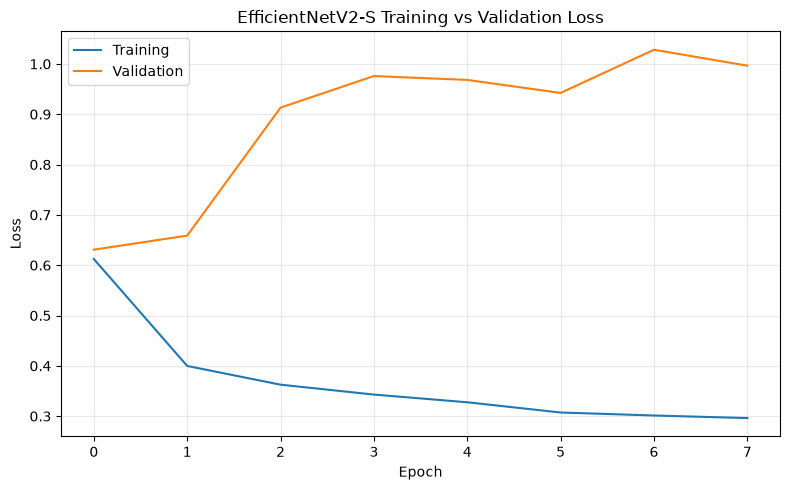

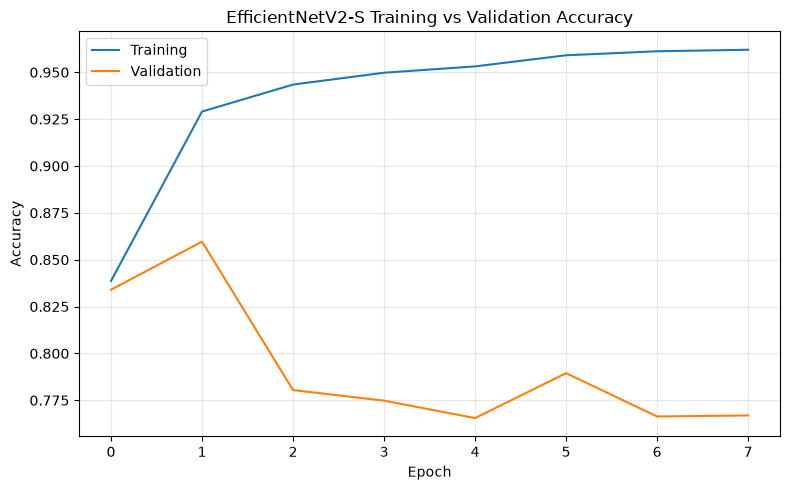

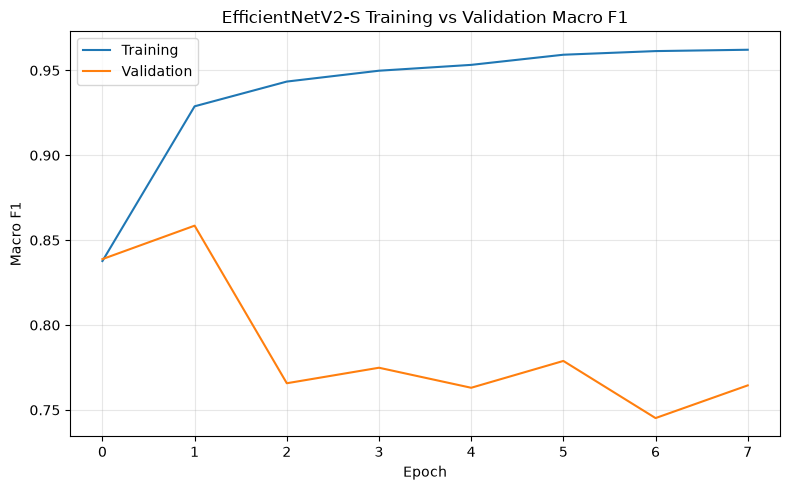

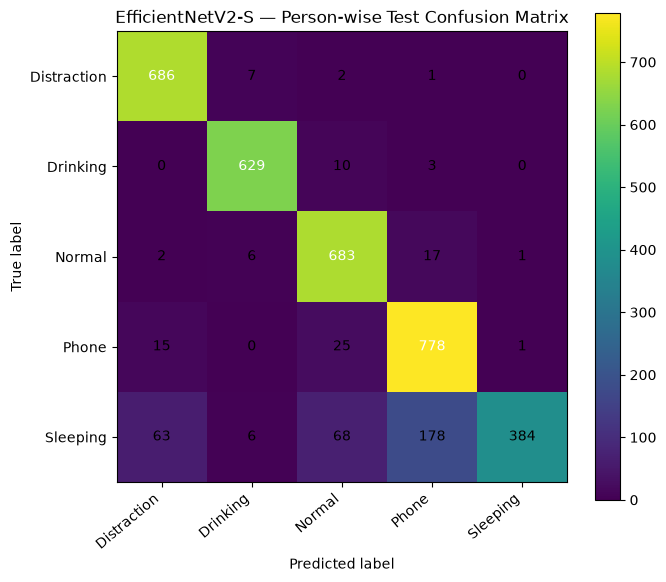

All results saved in: C:\Btech\SEM5\cuda\DL\EfficientNetV2S_Personwise_Results


In [12]:
def save_curve(train_values, val_values, title, ylabel, filename):
    plt.figure(figsize=(8, 5))
    plt.plot(train_values, label="Training")
    plt.plot(val_values, label="Validation")
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=300)
    plt.show()

save_curve(history["train_loss"], history["val_loss"],
           "EfficientNetV2-S Training vs Validation Loss", "Loss", "loss_curve.png")
save_curve(history["train_acc"], history["val_acc"],
           "EfficientNetV2-S Training vs Validation Accuracy", "Accuracy", "accuracy_curve.png")
save_curve(history["train_f1"], history["val_f1"],
           "EfficientNetV2-S Training vs Validation Macro F1", "Macro F1", "macro_f1_curve.png")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, interpolation="nearest")
ax.set_title("EfficientNetV2-S — Person-wise Test Confusion Matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_xticks(np.arange(len(CLASSES)))
ax.set_yticks(np.arange(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=40, ha="right")
ax.set_yticklabels(CLASSES)

threshold = cm.max() / 2 if cm.size else 0
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")

fig.colorbar(im)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=300)
plt.show()

print("All results saved in:", RESULTS_DIR.resolve())

## 11. Important notes for a fair comparison

1. This notebook is configured for the **person-wise split**: training participants, validation participant, and held-out test participant must remain separate.
2. Use the same split for your custom CNN and all benchmark models.
3. The model uses ImageNet pretrained weights. The first run may need internet access to download them.
4. The input is resized to 384 × 684 to approximately preserve the original 854 × 480 aspect ratio. Keep this preprocessing consistent across benchmark models where possible.
5. Do not use the test participant's results to select epochs, learning rates, or architectures.
6. Record the exact torchvision/PyTorch versions, GPU, training time, parameter count, and inference latency for the paper.
7. If CUDA runs out of memory, reduce `BATCH_SIZE` from 4 to 2. Do not increase it just to raise GPU utilization.